# Prog07: Self-Organizing Map (SOM) for Clustering Unlabeled Data


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs


# Generate sample unlabeled data


In [4]:
# Generate 2D data with 3 clusters
X, _ = make_blobs(n_samples=300, centers=3, n_features=2, random_state=42)
print(f"Data shape: {X.shape}")
print(f"Data range: X1=[{X[:,0].min():.2f}, {X[:,0].max():.2f}], X2=[{X[:,1].min():.2f}, {X[:,1].max():.2f}]")


Data shape: (300, 2)
Data range: X1=[-9.35, 6.95], X2=[-9.18, 11.73]


# SOM Implementation


In [5]:
class SOM:
    def __init__(self, grid_size, input_dim, learning_rate=0.1, sigma=1.0):
        self.grid_size = grid_size
        self.input_dim = input_dim
        self.learning_rate = learning_rate
        self.sigma = sigma
        
        # Initialize weights randomly
        self.weights = np.random.rand(grid_size, grid_size, input_dim)
        
    def find_bmu(self, input_vector):
        """Find Best Matching Unit (BMU)"""
        distances = np.sum((self.weights - input_vector) ** 2, axis=2)
        bmu_idx = np.unravel_index(np.argmin(distances), distances.shape)
        return bmu_idx
    
    def get_neighborhood(self, bmu_idx, current_sigma):
        """Calculate neighborhood function"""
        x, y = np.meshgrid(np.arange(self.grid_size), np.arange(self.grid_size))
        distances = np.sqrt((x - bmu_idx[0])**2 + (y - bmu_idx[1])**2)
        neighborhood = np.exp(-(distances**2) / (2 * current_sigma**2))
        return neighborhood
    
    def train(self, data, epochs=100):
        """Train the SOM"""
        n_samples = len(data)
        
        for epoch in range(epochs):
            # Decay learning rate and sigma
            current_lr = self.learning_rate * np.exp(-epoch / epochs)
            current_sigma = self.sigma * np.exp(-epoch / epochs)
            
            # Shuffle data
            indices = np.random.permutation(n_samples)
            
            for idx in indices:
                input_vector = data[idx]
                
                # Find BMU
                bmu_idx = self.find_bmu(input_vector)
                
                # Calculate neighborhood
                neighborhood = self.get_neighborhood(bmu_idx, current_sigma)
                
                # Update weights
                for i in range(self.grid_size):
                    for j in range(self.grid_size):
                        self.weights[i, j] += current_lr * neighborhood[i, j] * (input_vector - self.weights[i, j])
    
    def predict(self, data):
        """Assign each data point to its BMU"""
        predictions = []
        for input_vector in data:
            bmu_idx = self.find_bmu(input_vector)
            predictions.append(bmu_idx)
        return np.array(predictions)


# Train SOM


In [6]:
# Create and train SOM
som = SOM(grid_size=10, input_dim=2, learning_rate=0.1, sigma=3.0)
print("Training SOM...")
som.train(X, epochs=100)
print("Training completed!")


Training SOM...
Training completed!


# Visualization


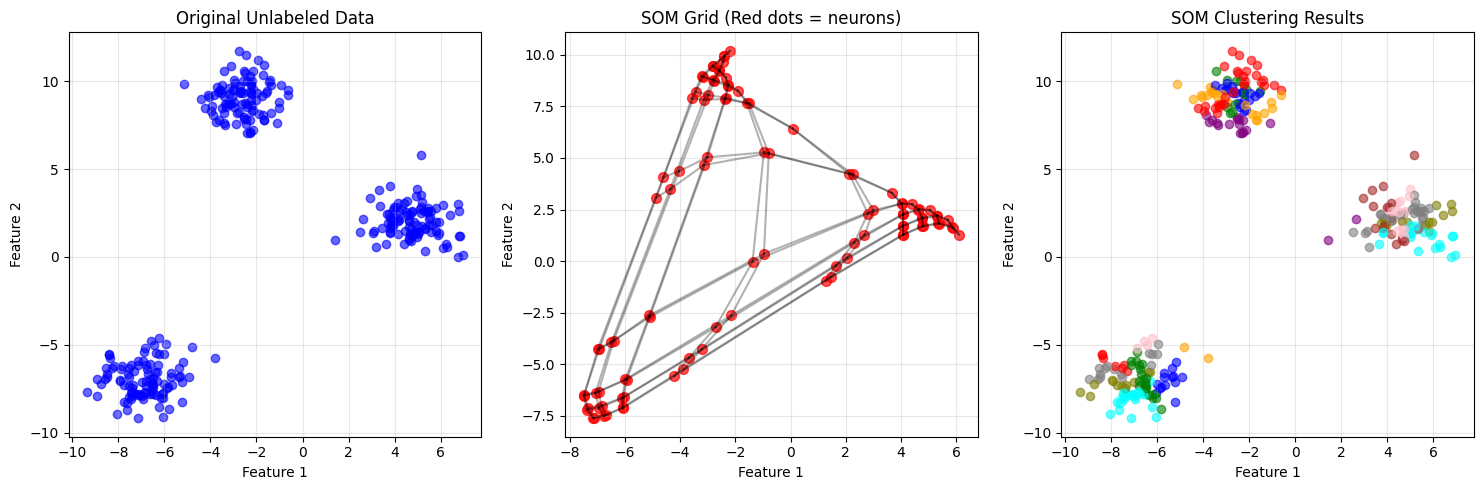

In [7]:
# Plot original data
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.scatter(X[:, 0], X[:, 1], alpha=0.6, c='blue')
plt.title('Original Unlabeled Data')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.grid(True, alpha=0.3)

# Plot SOM grid
plt.subplot(1, 3, 2)
for i in range(som.grid_size):
    for j in range(som.grid_size):
        plt.scatter(som.weights[i, j, 0], som.weights[i, j, 1], 
                   c='red', s=50, alpha=0.7)
        if i < som.grid_size-1:
            plt.plot([som.weights[i, j, 0], som.weights[i+1, j, 0]], 
                    [som.weights[i, j, 1], som.weights[i+1, j, 1]], 'k-', alpha=0.3)
        if j < som.grid_size-1:
            plt.plot([som.weights[i, j, 0], som.weights[i, j+1, 0]], 
                    [som.weights[i, j, 1], som.weights[i, j+1, 1]], 'k-', alpha=0.3)

plt.title('SOM Grid (Red dots = neurons)')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.grid(True, alpha=0.3)

# Plot clustering results
plt.subplot(1, 3, 3)
predictions = som.predict(X)
colors = ['red', 'green', 'blue', 'orange', 'purple', 'brown', 'pink', 'gray', 'olive', 'cyan']
for i, (x, pred) in enumerate(zip(X, predictions)):
    color_idx = pred[0] * som.grid_size + pred[1]
    plt.scatter(x[0], x[1], c=colors[color_idx % len(colors)], alpha=0.6)

plt.title('SOM Clustering Results')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# Display clustering statistics


In [8]:
# Analyze clustering results
unique_clusters, counts = np.unique([f"{p[0]},{p[1]}" for p in predictions], return_counts=True)
print(f"Number of clusters found: {len(unique_clusters)}")
print(f"Cluster distribution:")
for i, (cluster, count) in enumerate(zip(unique_clusters, counts)):
    print(f"  Cluster {cluster}: {count} points")

# Show some example predictions
print(f"\nSample predictions:")
for i in range(10):
    print(f"Data point {i}: {X[i]} -> Cluster {predictions[i]}")


Number of clusters found: 68
Cluster distribution:
  Cluster 0,0: 16 points
  Cluster 0,1: 4 points
  Cluster 0,2: 6 points
  Cluster 0,3: 12 points
  Cluster 0,4: 4 points
  Cluster 0,6: 3 points
  Cluster 0,7: 10 points
  Cluster 0,8: 9 points
  Cluster 0,9: 16 points
  Cluster 1,0: 2 points
  Cluster 1,1: 2 points
  Cluster 1,2: 4 points
  Cluster 1,3: 1 points
  Cluster 1,4: 2 points
  Cluster 1,6: 1 points
  Cluster 1,8: 1 points
  Cluster 1,9: 6 points
  Cluster 2,0: 2 points
  Cluster 2,1: 1 points
  Cluster 2,2: 7 points
  Cluster 2,3: 1 points
  Cluster 2,4: 9 points
  Cluster 2,7: 5 points
  Cluster 2,8: 2 points
  Cluster 2,9: 1 points
  Cluster 3,0: 5 points
  Cluster 3,1: 2 points
  Cluster 3,2: 3 points
  Cluster 3,3: 6 points
  Cluster 3,4: 1 points
  Cluster 4,0: 6 points
  Cluster 4,1: 2 points
  Cluster 4,3: 2 points
  Cluster 4,7: 4 points
  Cluster 5,5: 5 points
  Cluster 5,6: 2 points
  Cluster 5,7: 7 points
  Cluster 5,8: 3 points
  Cluster 5,9: 3 points
  Cluster